In [1]:
# Общие импорты и локальные данные JERICHON
import os, sys
from pathlib import Path

_HERE = Path(globals().get("__vsc_ipynb_file__", Path.cwd())).expanduser().resolve()
_CANDIDATES = [_HERE, *_HERE.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = next((p for p in dict.fromkeys(_CANDIDATES)
                     if (p / "src" / "data" / "load_data.py").is_file()
                     and (p / "research").is_dir()), None)
if PROJECT_ROOT is None and os.environ.get("JERICHON_PROJECT_ROOT"):
    PROJECT_ROOT = Path(os.environ["JERICHON_PROJECT_ROOT"]).expanduser().resolve()
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "data" / "load_data.py").is_file():
    raise FileNotFoundError("Не найден корень JERICHON с src/data/load_data.py")
sys.path[:0] = [str(PROJECT_ROOT), str(PROJECT_ROOT / "data")]
from src.data.load_data import *
ROOT = PROJECT_ROOT


# JERICHON — Event vs Control: исследование признаков в точках разворота

**Гипотеза:** признаки на барах значимых экстремумов статистически отличаются от признаков в случайных репрезентативных точках, не являющихся экстремумами.

## Определение события (важно)
Пороги **0,5%, 1% и 2,5% — это последующее движение против предшествующего направления**, подтверждающее разворот.

- Цена росла → фиксируем максимум-кандидат → событие подтверждается, когда цена падает от него на заданный процент.
- Цена падала → фиксируем минимум-кандидат → событие подтверждается, когда цена растёт от него на заданный процент.

Признаки берём **на баре самого экстремума (`pivot_ts`)**, а не на баре подтверждения (`confirmation_ts`). Будущее используется только для ретроспективной разметки событий, не для X.

Контрольные точки сопоставляются по тикеру, времени торговой сессии и квантилю недавней волатильности. Это event study, не торговая стратегия и не бэктест.


In [2]:
from pathlib import Path
import os, sys, json, re, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, ks_2samp
from IPython.display import display

# ===== Прямые пути =====
PROJECT_ROOT = ROOT
DATA_ROOT    = PROJECT_ROOT / "data"
LABELING_ROOT = PROJECT_ROOT / "src" / "data" / "labeling"
BUILDERS_ROOT = PROJECT_ROOT / "src" / "data" / "builders"

# Добавляем корень проекта в sys.path для импортов `from src.data.xxx import ...`
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Канонические helper-функции JERICHON (Dollar Bars / Base / Super Candles)
from src.data.builders import jerichon_feature_pipeline as jfp

OUTPUT_DIR = PROJECT_ROOT / "research" / "nowcasting" / "mark_4" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Локальная загрузка через helper-функции pipeline (build_feature_dataset сломан — в нём баг с archive())
DATA_MODE = "local"

TICKERS = ["GAZP", "SBER", "VTBR", "LKOH", "SMLT"]
START_DATE, END_DATE = "2026-06-01", "2026-11-03"
DOLLAR_THRESHOLD = 10_000_000

REVERSAL_THRESHOLDS = [0.005, 0.01, 0.025]
CONTROL_MULTIPLIER = 3
EXCLUSION_RADIUS_BARS = 10
TOD_BUCKET_MINUTES = 30
VOL_LOOKBACK = 50
VOL_BINS = 5
RANDOM_SEED = 63
MAX_FEATURES = None  # например 100 для быстрого smoke test

## 1. Загрузка канонического датасета

Ожидается одна строка на бар, `bar_ts`, `close` и причинно рассчитанные признаки. По архитектуре JERICHON это полный feature space из 474 признаков; provenance-поля используются для аудита, но не включаются в статистические тесты.

Если локальная сигнатура `build_feature_dataset` отличается, поправь только вызов в `load_pipeline()`.

In [3]:
def load_local_history(history_root, ticker):
    """Загрузка локальных parquet-файлов вместо вызова build_feature_dataset."""
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    dates = sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")
    
    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")
    
    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING read {p}: {repr(e)}")
        
        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING read {p}: {repr(e)}")
    
    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников {missing} для {ticker}")
    
    print(f"[{ticker}] Дат: {len(dates)} | {dates[0]} → {dates[-1]}")
    return out, dates


def build_features_for_ticker(ticker, dollar_threshold=DOLLAR_THRESHOLD):
    """Построение 474 признаков для одного тикера через helper-функции pipeline."""
    data, dates = load_local_history(HISTORY_ROOT, ticker)
    
    # Dollar Bars
    bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=int(dollar_threshold))
    if bars is None or bars.empty:
        raise RuntimeError(f"Dollar Bars пусты для {ticker}")
    
    if "bar_ts" not in bars.columns:
        if "close_time" not in bars.columns:
            raise RuntimeError(f"В bars нет bar_ts/close_time для {ticker}")
        bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
    else:
        bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
    
    bars = (bars.dropna(subset=["bar_ts"])
                 .sort_values("bar_ts")
                 .drop_duplicates("bar_ts", keep="last")
                 .reset_index(drop=True))
    
    # Base features
    base_raw = jfp._base(bars.copy())
    if isinstance(base_raw, tuple):
        base_raw = base_raw[0]
    if not isinstance(base_raw, pd.DataFrame):
        raise TypeError(f"_base должен вернуть DataFrame для {ticker}")
    
    if "bar_ts" not in base_raw.columns:
        if "close_time" in base_raw.columns:
            base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
        elif isinstance(base_raw.index, pd.DatetimeIndex):
            base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
        elif "ts" in base_raw.columns:
            base_raw = base_raw.rename(columns={"ts": "bar_ts"})
        else:
            raise RuntimeError(f"Не найден временной ключ в _base output для {ticker}")
    
    base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
    base_raw = (base_raw.dropna(subset=["bar_ts"])
                        .sort_values("bar_ts")
                        .drop_duplicates("bar_ts", keep="last")
                        .reset_index(drop=True))
    
    # Super Candle features
    bars_for_sc = bars.copy()
    if "ts" not in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    if "CLOSE" not in bars_for_sc.columns:
        if "close" in bars_for_sc.columns:
            bars_for_sc["CLOSE"] = bars_for_sc["close"]
        else:
            raise KeyError(f"В bars отсутствует CLOSE/close для {ticker}")
    
    bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)
    bars_for_sc = bars_for_sc.dropna(subset=["ts"]).sort_values("ts").reset_index(drop=True)
    
    sc_result = jfp._build_sc_features(data, bars_for_sc)
    feature_frames = sc_result[0] if isinstance(sc_result, tuple) else sc_result
    if not isinstance(feature_frames, dict):
        raise TypeError(f"_build_sc_features должен возвращать dict для {ticker}")
    
    # Availability + causal attach
    for source in ("tradestats", "obstats", "orderstats"):
        if data[source].empty:
            raise RuntimeError(f"Локальный источник {source} пуст для {ticker}")
        jfp._choose_availability(data[source].copy(), source)
    
    def resolve_feature_frame(source, frames):
        if source in frames:
            return frames[source]
        matches = [k for k in frames if source.lower() in str(k).lower()]
        if len(matches) == 1:
            return frames[matches[0]]
        raise RuntimeError(f"Не удалось сопоставить {source} с feature frame для {ticker}")
    
    causal = bars.copy()
    for source in ("tradestats", "obstats", "orderstats"):
        feature_frame = resolve_feature_frame(source, feature_frames)
        attached = jfp._attach_source(causal, feature_frame, data[source], source)
        if isinstance(attached, pd.DataFrame):
            causal = attached
    
    # Merge base features
    base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
    if len(base_cols) != 73:
        raise RuntimeError(f"Ожидалось 73 base features для {ticker}, найдено {len(base_cols)}")
    
    base_join = base_raw[["bar_ts"] + base_cols].copy()
    base_join = base_join.rename(columns={c: f"base {c}" for c in base_cols})
    causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
    causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")
    
    # Feature inventory
    provenance_cols = [c for c in causal.columns if c.endswith("__event_ts") or c.endswith("__available_at")]
    sc_prefixes = ("tradestats", "obstats", "orderstats")
    sc_feature_cols = [c for c in causal.columns
                       if c.startswith(sc_prefixes)
                       and c not in provenance_cols
                       and pd.api.types.is_numeric_dtype(causal[c])]
    base_cols_renamed = [c for c in causal.columns if c.startswith("base ")]
    feature_cols = base_cols_renamed + sc_feature_cols
    
    if len(feature_cols) != 474:
        raise RuntimeError(f"Feature inventory mismatch для {ticker}: {len(feature_cols)} != 474")
    
    # Цена закрытия нужна для ретроспективной разметки directional change.
    # Она НЕ входит в 474 ML features и не участвует в сравнении X.
    close_col = next((c for c in ("close", "CLOSE") if c in bars.columns), None)
    if close_col is None:
        raise KeyError(
            f"Dollar Bars для {ticker}: нет close/CLOSE. "
            f"Доступные колонки: {list(bars.columns)}"
        )

    price_frame = bars[["bar_ts", close_col]].copy()
    if close_col != "close":
        price_frame = price_frame.rename(columns={close_col: "close"})
    price_frame["close"] = pd.to_numeric(price_frame["close"], errors="coerce")
    if price_frame["close"].isna().any():
        bad_n = int(price_frame["close"].isna().sum())
        raise ValueError(f"{ticker}: {bad_n} Dollar Bars имеют нечисловой close")

    ft = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
    ft = ft.merge(price_frame, on="bar_ts", how="left", validate="one_to_one")
    if ft["close"].isna().any():
        raise RuntimeError(
            f"{ticker}: после привязки цены потеряно "
            f"{int(ft['close'].isna().sum())} значений close"
        )

    ft = ft.sort_values("bar_ts").reset_index(drop=True)
    ft["ticker"] = ticker
    return ft, bars


# Загрузка всех тикеров
parts = []
for t in TICKERS:
    print(f"Loading {t}")
    try:
        ft, _ = build_features_for_ticker(t)
        parts.append(ft)
    except Exception as e:
        print(f"  SKIP {t}: {e}")

if not parts:
    raise ValueError("Не удалось загрузить ни один тикер")

data = pd.concat(parts, ignore_index=True).sort_values(["ticker", "bar_ts"]).reset_index(drop=True)

# Нормализуем имя колонки close
if "CLOSE" in data.columns and "close" not in data.columns:
    data["close"] = data["CLOSE"]
if "close" not in data.columns:
    raise ValueError("Нужна колонка close/CLOSE для directional-change разметки")

print("Rows:", len(data), "| tickers:", data.ticker.nunique())
display(data.groupby("ticker").agg(rows=("bar_ts", "size"),
                                    start=("bar_ts", "min"),
                                    end=("bar_ts", "max")))

Loading GAZP
[GAZP] Дат: 33 | 2026-09-24 → 2026-11-19


C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performanc

Loading SBER
  SKIP SBER: Для SBER не найдены сохранённые даты в C:\JERICHON-Git\JERICHON\data
Loading VTBR
[VTBR] Дат: 50 | 2026-08-28 → 2026-11-19


C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\JERICHON-Git\JERICHON\src\data\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performanc

Loading LKOH
  SKIP LKOH: Для LKOH не найдены сохранённые даты в C:\JERICHON-Git\JERICHON\data
Loading SMLT
  SKIP SMLT: Для SMLT не найдены сохранённые даты в C:\JERICHON-Git\JERICHON\data
Rows: 39531 | tickers: 2


,rows,start,end
ticker,,,
GAZP,22901,2026-09-24 03:59:40+00:00,2026-11-19 17:56:01+00:00
VTBR,16630,2026-08-28 04:02:32+00:00,2026-11-19 18:02:16+00:00


## 2. Выбор признаков и causal audit

Исключаем цены/объёмы как сырые поля, идентификаторы, timestamps, provenance и любые явно будущие/label-поля. Если присутствуют `available_at` и `event_ts`, проверяем, что они не позже `bar_ts`.

In [5]:
NON_FEATURE = {
    "bar_ts","timestamp","ts","datetime","time","ticker",
    "open","high","low","close","volume","value","turnover",
    "event_ts","available_at","systime","confirmation_ts"
}
FUTURE_RE = re.compile(r"(^|_)(target|label|future|lead|forward|pivot|confirmation|event_id)(_|$)", re.I)
FEATURES = [c for c in data.columns
            if c.lower() not in NON_FEATURE
            and pd.api.types.is_numeric_dtype(data[c])
            and not FUTURE_RE.search(c.lower())]
if MAX_FEATURES is not None: FEATURES = FEATURES[:MAX_FEATURES]
print("Feature candidates:", len(FEATURES))

# В каноническом датасете provenance обычно имеет имена вида
# tradestats__event_ts / tradestats__available_at.
provenance_cols = [
    c for c in data.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
    or c in ("event_ts", "available_at")
]
for c in provenance_cols:
    data[c] = pd.to_datetime(data[c], errors="coerce", utc=True)
    bad = data[c].notna() & (data[c] > data["bar_ts"])
    print(c, "future rows:", int(bad.sum()))
    if bad.any():
        raise ValueError(f"Causal audit failed: {c} > bar_ts")


Feature candidates: 474
tradestats__event_ts future rows: 0
tradestats__available_at future rows: 0
obstats__event_ts future rows: 0
obstats__available_at future rows: 0
orderstats__event_ts future rows: 0
orderstats__available_at future rows: 0


## 3. Разворотные события: directional change

Используем close-to-close алгоритм, чтобы избежать неоднозначного порядка high/low внутри одной свечи. Он отслеживает текущий экстремум и подтверждает его после обратного движения на заданный процент.

`pivot_idx` — бар экстремума; `confirm_idx` — бар подтверждения. `prior_leg_return` — доходность от предыдущего подтверждённого экстремума до текущего pivot. Начальная неустановленная часть серии может быть пропущена.

In [6]:
def directional_change(close, threshold):
    x = pd.to_numeric(close, errors="coerce").to_numpy(float)
    out, n = [], len(x)
    if n < 3: return out
    direction, extreme_i, extreme_p = 0, 0, x[0]
    last_pivot_price = None

    for i in range(1, n):
        p = x[i]
        if not np.isfinite(p) or p <= 0: continue
        if direction == 0:
            if p >= extreme_p * (1 + threshold):
                direction, extreme_i, extreme_p = 1, i, p
            elif p <= extreme_p * (1 - threshold):
                direction, extreme_i, extreme_p = -1, i, p
            continue

        if direction == 1:  # рост; ищем вершину
            if p >= extreme_p:
                extreme_i, extreme_p = i, p
            elif p <= extreme_p * (1 - threshold):
                prior = extreme_p / last_pivot_price - 1 if last_pivot_price else np.nan
                out.append(dict(pivot_idx=extreme_i, confirm_idx=i, pivot_price=extreme_p,
                                direction="peak", prior_leg_return=prior,
                                confirmation_delay_bars=i-extreme_i, threshold=threshold))
                last_pivot_price = extreme_p
                direction, extreme_i, extreme_p = -1, i, p
        else:  # падение; ищем дно
            if p <= extreme_p:
                extreme_i, extreme_p = i, p
            elif p >= extreme_p * (1 + threshold):
                prior = extreme_p / last_pivot_price - 1 if last_pivot_price else np.nan
                out.append(dict(pivot_idx=extreme_i, confirm_idx=i, pivot_price=extreme_p,
                                direction="trough", prior_leg_return=prior,
                                confirmation_delay_bars=i-extreme_i, threshold=threshold))
                last_pivot_price = extreme_p
                direction, extreme_i, extreme_p = 1, i, p
    return out

event_rows = []
for ticker, g0 in data.groupby("ticker", sort=False):
    g = g0.sort_values("bar_ts").reset_index(drop=True)
    for th in REVERSAL_THRESHOLDS:
        for e in directional_change(g.close, th):
            event_rows.append({
                "ticker": ticker, **e,
                "pivot_ts": g.loc[e["pivot_idx"], "bar_ts"],
                "confirmation_ts": g.loc[e["confirm_idx"], "bar_ts"]
            })
events = pd.DataFrame(event_rows)
if events.empty: raise ValueError("События не найдены: проверь период, close и пороги")
print("Events:", len(events))
display(events.groupby(["ticker","threshold","direction"]).size().unstack(fill_value=0))


Events: 3132


direction         peak  trough
ticker threshold              
GAZP   0.005       120     120
       0.010        34      35
       0.025         4       5
LKOH   0.005       189     188
       0.010        50      50
       0.025         8       8
SBER   0.005       257     257
       0.010       122     123
       0.025        49      48
SMLT   0.005       282     283
       0.010       118     119
       0.025        22      23
VTBR   0.005       218     217
       0.010        84      83
       0.025         8       8

## 4. Контрольная выборка

Для каждой event-точки случайно выбираем до трёх control-точек:
- тот же тикер;
- та же 30-минутная корзина торгового времени;
- тот же квантиль rolling volatility (если точных совпадений мало, matching ослабляется);
- вне окрестности всех pivot-событий на `EXCLUSION_RADIUS_BARS`.

Контроль выбирается без возвращения внутри тикера и порога. Seed фиксирован.

In [7]:
data["tod_min"] = data.bar_ts.dt.hour * 60 + data.bar_ts.dt.minute
data["tod_bin"] = (data.tod_min // TOD_BUCKET_MINUTES).astype(int)
data["ret1"] = data.groupby("ticker").close.pct_change()
data["rv"] = data.groupby("ticker").ret1.transform(
    lambda s: s.rolling(VOL_LOOKBACK, min_periods=max(10, VOL_LOOKBACK//3)).std()
)
data["vol_bin"] = 1
for ticker, idx in data.groupby("ticker").groups.items():
    s = data.loc[idx, "rv"]
    valid = s.notna()
    if valid.sum() >= VOL_BINS * 3:
        data.loc[s[valid].index, "vol_bin"] = np.ceil(
            s[valid].rank(method="first", pct=True) * VOL_BINS
        ).clip(1, VOL_BINS).astype(int)

# Local indices of all detected extrema, separately by ticker.
all_pivots = {t: set() for t in data.ticker.unique()}
for r in events.itertuples():
    all_pivots[r.ticker].add(int(r.pivot_idx))

def make_controls(th):
    rng = np.random.default_rng(RANDOM_SEED + int(th*10000))
    ev = events[np.isclose(events.threshold, th)]
    controls = []
    for ticker, eg in ev.groupby("ticker"):
        g = data[data.ticker == ticker].sort_values("bar_ts").reset_index(drop=True)
        blocked = np.zeros(len(g), dtype=bool)
        for pi in all_pivots[ticker]:
            blocked[max(0,pi-EXCLUSION_RADIUS_BARS):min(len(g),pi+EXCLUSION_RADIUS_BARS+1)] = True
        cand = g.loc[~blocked].copy()
        cand["local_idx"] = np.flatnonzero(~blocked)
        for e in eg.itertuples():
            pivot = g.iloc[int(e.pivot_idx)]
            m = cand[(cand.tod_bin == pivot.tod_bin) & (cand.vol_bin == pivot.vol_bin)]
            if len(m) < CONTROL_MULTIPLIER:
                m = cand[cand.tod_bin == pivot.tod_bin]
            if len(m) < CONTROL_MULTIPLIER:
                m = cand
            if m.empty: continue
            chosen = rng.choice(m.index.to_numpy(), size=min(CONTROL_MULTIPLIER,len(m)), replace=False)
            for ix in chosen:
                c = m.loc[ix]
                controls.append(dict(ticker=ticker, threshold=th, pivot_idx=int(c.local_idx),
                                     control_ts=c.bar_ts, matched_event_ts=e.pivot_ts))
    return pd.DataFrame(controls)

controls = {th: make_controls(th) for th in REVERSAL_THRESHOLDS}
for th,c in controls.items(): print(f"{th:.2%}: {len(c)} controls")


0.50%: 6393 controls
1.00%: 2454 controls
2.50%: 549 controls


## 5. Сравнение распределений

Для каждого признака рассчитываем средние/медианы, standardized mean difference (SMD), Mann–Whitney U и Kolmogorov–Smirnov. Затем применяем Benjamini–Hochberg FDR отдельно внутри каждого порога. SMD отражает размер эффекта, p-value — статистическую совместимость с нулевой гипотезой.

In [8]:
def bh_fdr(p):
    p = np.asarray(p, float); n = len(p)
    order = np.argsort(p); ranked = p[order]
    q = ranked * n / np.arange(1,n+1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[order] = np.clip(q,0,1)
    return out

def vals(s):
    return pd.to_numeric(s, errors="coerce").replace([np.inf,-np.inf],np.nan).dropna().to_numpy()

def rows_at(meta):
    parts = []
    for ticker, sub in meta.groupby("ticker"):
        g = data[data.ticker == ticker].sort_values("bar_ts").reset_index(drop=True)
        ii = sub.pivot_idx.astype(int).to_numpy()
        ii = ii[(ii >= 0) & (ii < len(g))]
        if len(ii): parts.append(g.iloc[ii].copy())
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

def compare(ev, co, th):
    out=[]
    for f in FEATURES:
        a,b=vals(ev[f]),vals(co[f])
        if min(len(a),len(b)) < 10: continue
        va,vb=np.var(a,ddof=1),np.var(b,ddof=1)
        pooled=math.sqrt(((len(a)-1)*va+(len(b)-1)*vb)/max(1,len(a)+len(b)-2))
        smd=(a.mean()-b.mean())/pooled if pooled>0 else np.nan
        mw=mannwhitneyu(a,b,alternative="two-sided").pvalue
        ks=ks_2samp(a,b,alternative="two-sided",method="auto")
        out.append(dict(threshold=th,feature=f,n_event=len(a),n_control=len(b),
                        event_mean=a.mean(),control_mean=b.mean(),
                        event_median=np.median(a),control_median=np.median(b),
                        smd=smd,abs_smd=abs(smd),mw_p=mw,ks_stat=ks.statistic,ks_p=ks.pvalue))
    z=pd.DataFrame(out)
    if len(z):
        z["mw_q"]=bh_fdr(z.mw_p.fillna(1))
        z["ks_q"]=bh_fdr(z.ks_p.fillna(1))
    return z

stats=[]
ticker_stats=[]
for th in REVERSAL_THRESHOLDS:
    em=events[np.isclose(events.threshold,th)]
    cm=controls[th]
    er,cr=rows_at(em),rows_at(cm)
    z=compare(er,cr,th)
    if len(z): stats.append(z)
    for ticker in sorted(data["ticker"].dropna().unique()):
        a0,b0=er[er.ticker==ticker],cr[cr.ticker==ticker]
        if min(len(a0),len(b0))<10: continue
        for f in FEATURES:
            a,b=vals(a0[f]),vals(b0[f])
            if min(len(a),len(b))<10: continue
            sd=math.sqrt((np.var(a,ddof=1)+np.var(b,ddof=1))/2)
            ticker_stats.append(dict(threshold=th,ticker=ticker,feature=f,
                                     smd=(a.mean()-b.mean())/sd if sd>0 else np.nan))
feature_stats=pd.concat(stats,ignore_index=True) if stats else pd.DataFrame()
ticker_stats=pd.DataFrame(ticker_stats)
print("Feature tests:",len(feature_stats),"| ticker-level rows:",len(ticker_stats))


Feature tests: 1422 | ticker-level rows: 6636


## 6. Итоговые таблицы и устойчивость между тикерами

Не интерпретируй один маленький p-value как найденный сигнал. Ищи одновременно заметный размер эффекта, FDR-значимость и одинаковое направление эффекта у разных тикеров.

In [9]:
if feature_stats.empty:
    print("Недостаточно наблюдений для сравнения")
else:
    overview=feature_stats.groupby("threshold").agg(
        tested=("feature","count"),
        mw_q05=("mw_q",lambda s:int((s<.05).sum())),
        ks_q05=("ks_q",lambda s:int((s<.05).sum())),
        abs_smd_ge_02=("abs_smd",lambda s:int((s>=.2).sum())),
        abs_smd_ge_05=("abs_smd",lambda s:int((s>=.5).sum())),
        median_abs_smd=("abs_smd","median")
    ).reset_index()
    display(overview)
    for th in REVERSAL_THRESHOLDS:
        print(f"TOP features for {th:.2%}")
        display(feature_stats[np.isclose(feature_stats.threshold,th)]
                .sort_values(["mw_q","abs_smd"],ascending=[True,False]).head(25))

consistency=[]
for r in feature_stats.itertuples():
    sub=ticker_stats[np.isclose(ticker_stats.threshold,r.threshold) & (ticker_stats.feature==r.feature)]
    sub=sub[np.isfinite(sub.smd)]
    if len(sub):
        consistency.append(dict(threshold=r.threshold,feature=r.feature,
            tickers=len(sub),same_sign=int((np.sign(sub.smd)==np.sign(r.smd)).sum()),
            sign_consistency=float((np.sign(sub.smd)==np.sign(r.smd)).mean()),
            pooled_smd=r.smd,abs_smd=r.abs_smd,mw_q=r.mw_q))
consistency_df=pd.DataFrame(consistency)
if len(consistency_df):
    for th in REVERSAL_THRESHOLDS:
        print("Cross-ticker consistency",f"{th:.2%}")
        display(consistency_df[np.isclose(consistency_df.threshold,th)]
                .sort_values(["sign_consistency","abs_smd"],ascending=False).head(20))


,threshold,tested,mw_q05,ks_q05,abs_smd_ge_02,abs_smd_ge_05,median_abs_smd
0,0.005,474,236,428,7,0,0.037363
1,0.010,474,187,354,30,1,0.053445
2,0.025,474,206,363,160,24,0.120463


TOP features for 0.50%


,threshold,feature,n_event,n_control,event_mean,control_mean,event_median,control_median,smd,abs_smd,mw_p,ks_stat,ks_p,mw_q,ks_q
72,0.005,base base__close_div_atr,2131,6393,6.147222e+02,8.695075e+02,3.954146e+02,7.958595e+02,-0.389312,0.389312,3.090647e-125,0.306116,7.850595e-133,1.464967e-122,3.721182e-130
34,0.005,base base__close_roll_std_5,2131,6392,1.583293e+00,8.174759e-01,5.585696e-01,1.821538e-01,0.261519,0.261519,1.008826e-70,0.250704,8.218240e-89,2.390919e-68,1.947723e-86
40,0.005,base base__close_roll_std_10,2131,6392,1.924610e+00,1.174824e+00,7.471427e-01,2.603438e-01,0.244777,0.244777,2.601775e-51,0.186077,7.267478e-49,4.110805e-49,6.889569e-47
15,0.005,base base__atr,2131,6393,2.119112e+00,1.336705e+00,9.785714e-01,2.535714e-01,0.341672,0.341672,7.062135e-50,0.234632,1.190757e-77,8.368630e-48,1.881396e-75
71,0.005,base base__close_x_atr,2131,6393,6.006057e+03,5.321046e+03,2.488571e+02,7.076359e+01,0.054601,0.054601,5.985546e-30,0.215235,2.626433e-65,5.674298e-28,3.112323e-63
46,0.005,base base__close_roll_std_20,2131,6392,2.411782e+00,1.699685e+00,8.931906e-01,3.464933e-01,0.183189,0.183189,3.891632e-28,0.160572,2.033712e-36,2.635191e-26,1.204975e-34
13,0.005,base base__bb_width,2131,6392,9.647129e+00,6.798741e+00,3.572762e+00,1.385973e+00,0.183189,0.183189,3.891632e-28,0.160572,2.033712e-36,2.635191e-26,1.204975e-34
23,0.005,base base__month_sin,2131,6393,-9.001266e-01,-8.685959e-01,-1.000000e+00,-8.660254e-01,-0.196623,0.196623,2.542298e-22,0.118254,6.675622e-20,1.506312e-20,1.861320e-18
22,0.005,base base__dayofweek_cos,2131,6393,-2.414372e-01,-4.417066e-02,-9.009689e-01,-2.225209e-01,-0.256987,0.256987,2.663145e-18,0.144690,1.291470e-29,1.402590e-16,6.801740e-28
24,0.005,base base__month_cos,2131,6393,2.399313e-01,2.983218e-01,-1.836970e-16,5.000000e-01,-0.165299,0.165299,2.591574e-13,0.101830,7.351666e-15,1.228406e-11,1.024909e-13


TOP features for 1.00%


,threshold,feature,n_event,n_control,event_mean,control_mean,event_median,control_median,smd,abs_smd,mw_p,ks_stat,ks_p,mw_q,ks_q
546,0.01,base base__close_div_atr,818,2454,515.225484,850.696784,250.968581,715.175373,-0.434303,0.434303,1.423894e-87,0.437245,3.609362e-106,6.749258e-85,1.710838e-103
508,0.01,base base__close_roll_std_5,818,2454,1.518689,0.650214,0.576194,0.172583,0.454105,0.454105,1.697418e-53,0.310106,1.267062e-52,4.022881e-51,2.001958e-50
489,0.01,base base__atr,818,2454,2.454482,1.194545,1.042857,0.252500,0.568533,0.568533,1.627011e-48,0.315811,1.342731e-54,1.928008e-46,3.182273e-52
514,0.01,base base__close_roll_std_10,818,2454,1.783470,0.916677,0.886692,0.231519,0.415186,0.415186,1.599357e-48,0.276284,1.049649e-41,1.928008e-46,9.950670e-40
520,0.01,base base__close_roll_std_20,818,2454,2.189907,1.377351,1.100315,0.346493,0.261227,0.261227,7.287733e-35,0.226976,3.670370e-28,5.757309e-33,2.485365e-26
487,0.01,base base__bb_width,818,2454,8.759626,5.509403,4.401258,1.385973,0.261227,0.261227,7.287733e-35,0.226976,3.670370e-28,5.757309e-33,2.485365e-26
545,0.01,base base__close_x_atr,818,2454,4214.568628,3835.647842,265.218571,69.970071,0.035892,0.035892,1.208480e-26,0.292584,8.452454e-47,8.183135e-25,1.001616e-44
517,0.01,base base__close_roll_skew_10,818,2454,-0.326964,0.030045,-0.158615,0.027281,-0.425343,0.425343,1.941089e-14,0.188672,1.543262e-19,1.150095e-12,3.325028e-18
497,0.01,base base__month_sin,818,2454,-0.910842,-0.870961,-1.000000,-0.866025,-0.244749,0.244749,3.044917e-13,0.141809,3.383079e-11,1.603656e-11,3.144273e-10
496,0.01,base base__dayofweek_cos,818,2454,-0.320310,-0.039749,-0.900969,-0.222521,-0.366858,0.366858,1.280828e-12,0.218419,4.303218e-26,6.071123e-11,2.549657e-24


TOP features for 2.50%


... (3 outputs left out)

Cross-ticker consistency 1.00%


,threshold,feature,tickers,same_sign,sign_consistency,pooled_smd,abs_smd,mw_q
489,0.01,base base__atr,5,5,1.0,0.568533,0.568533,1.928008e-46
508,0.01,base base__close_roll_std_5,5,5,1.0,0.454105,0.454105,4.022881e-51
524,0.01,base base__close_roll_kurt_20,5,5,1.0,0.422313,0.422313,2.477013e-09
514,0.01,base base__close_roll_std_10,5,5,1.0,0.415186,0.415186,1.928008e-46
518,0.01,base base__close_roll_kurt_10,5,5,1.0,0.399562,0.399562,1.252697e-02
598,0.01,tradestats__ts_buy_volume_share_ma12,5,5,1.0,0.269734,0.269734,2.820250e-09
578,0.01,tradestats__ts_volume_imbalance_ma12,5,5,1.0,0.269734,0.269734,2.820250e-09
608,0.01,tradestats__ts_buy_value_share_ma12,5,5,1.0,0.269626,0.269626,2.820250e-09
588,0.01,tradestats__ts_value_imbalance_ma12,5,5,1.0,0.269626,0.269626,2.820250e-09
520,0.01,base base__close_roll_std_20,5,5,1.0,0.261227,0.261227,5.757309e-33


Cross-ticker consistency 2.50%


,threshold,feature,tickers,same_sign,sign_consistency,pooled_smd,abs_smd,mw_q
963,0.025,base base__atr,4,4,1.0,1.218597,1.218597,8.903199e-25
997,0.025,base base__close_roll_skew_20,4,4,1.0,-1.101452,1.101452,2.275234e-21
982,0.025,base base__close_roll_std_5,4,4,1.0,0.962237,0.962237,4.411462e-19
1020,0.025,base base__close_div_atr,4,4,1.0,-0.867758,0.867758,2.925343e-32
988,0.025,base base__close_roll_std_10,4,4,1.0,0.845586,0.845586,2.175558e-21
1082,0.025,tradestats__ts_buy_value_share_ma12,4,4,1.0,0.757764,0.757764,3.038714e-17
1062,0.025,tradestats__ts_value_imbalance_ma12,4,4,1.0,0.757764,0.757764,3.038714e-17
1052,0.025,tradestats__ts_volume_imbalance_ma12,4,4,1.0,0.757692,0.757692,3.038714e-17
1072,0.025,tradestats__ts_buy_volume_share_ma12,4,4,1.0,0.757692,0.757692,3.038714e-17
961,0.025,base base__bb_width,4,4,1.0,0.594863,0.594863,4.012316e-22


## 7. Распределения top-признаков

Гистограммы pooled event/control — первичная диагностика. При сильном результате дополнительно смотри тикерную устойчивость и повтори эксперимент на другом временном отрезке.

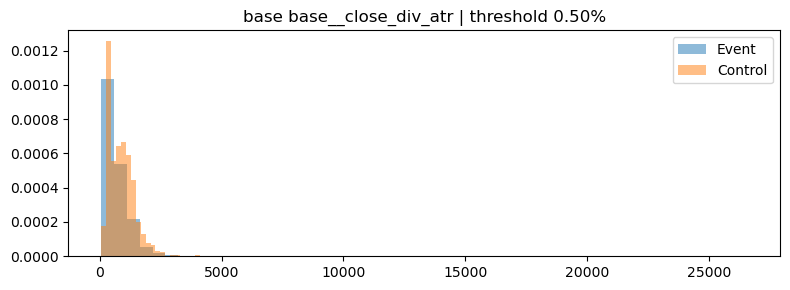

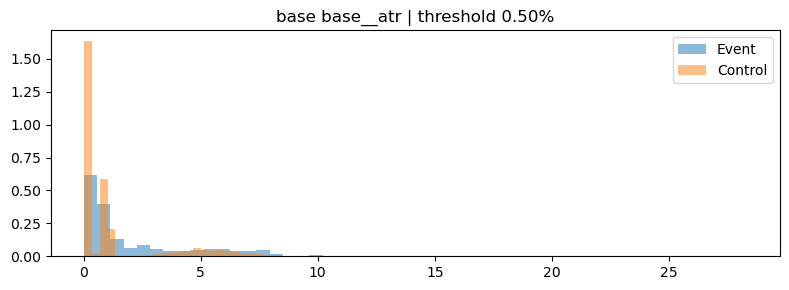

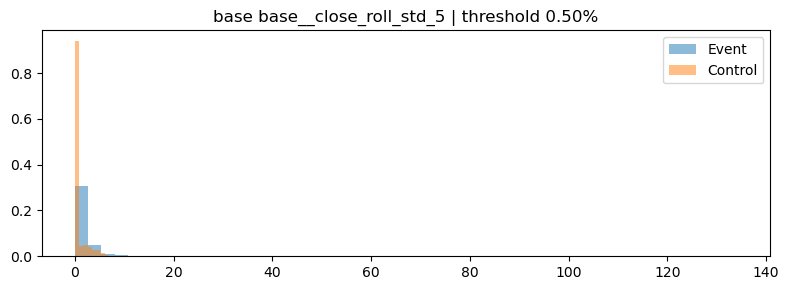

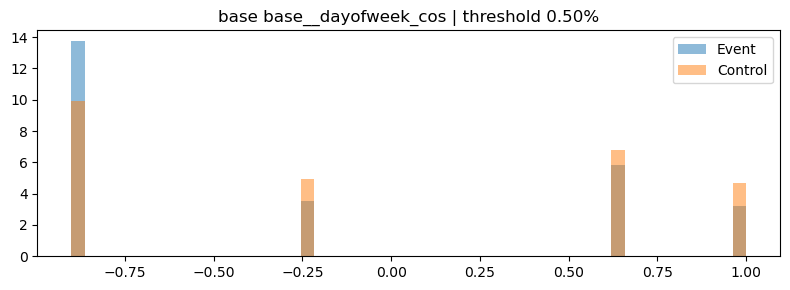

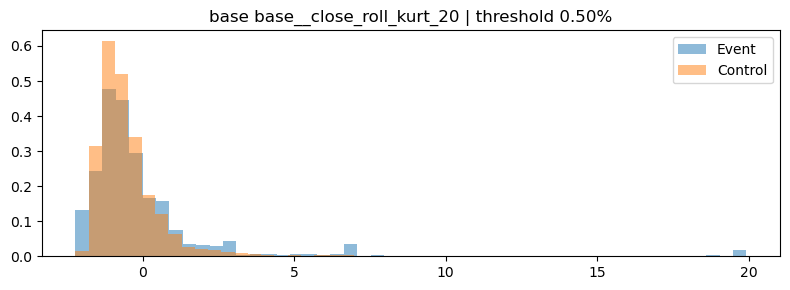

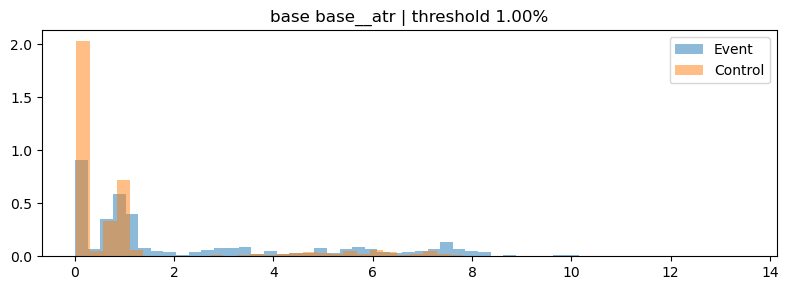

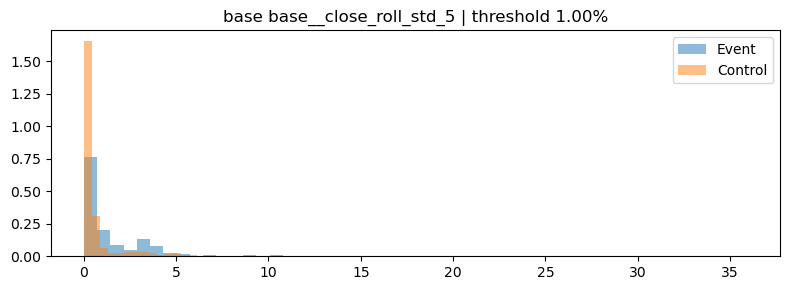

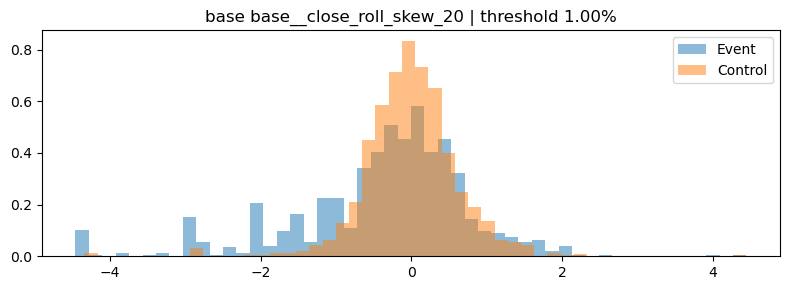

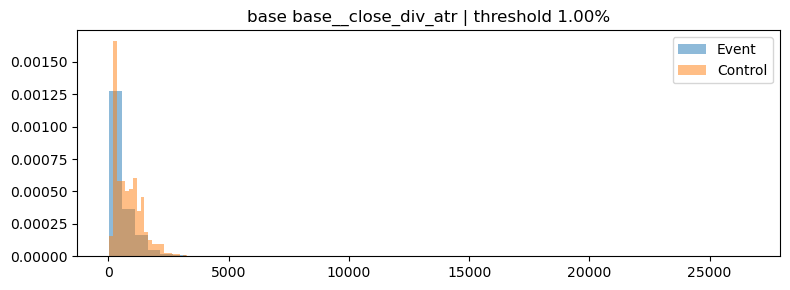

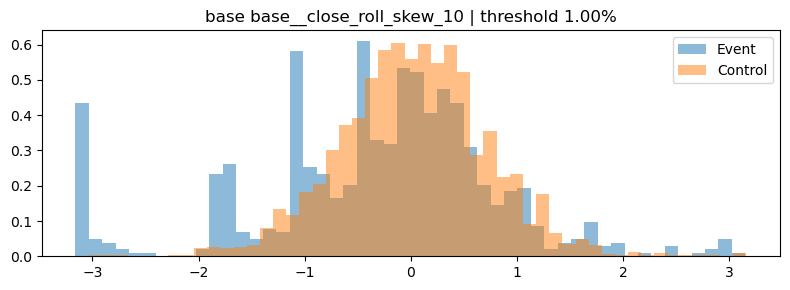

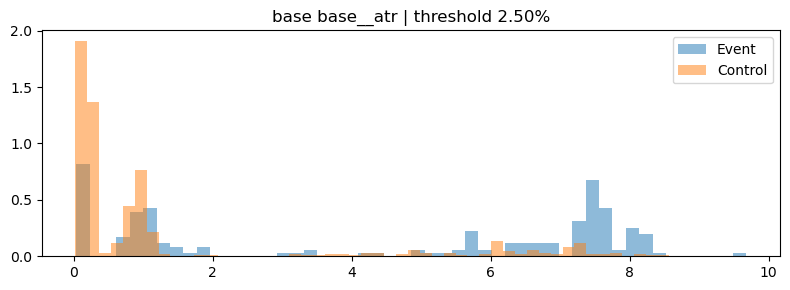

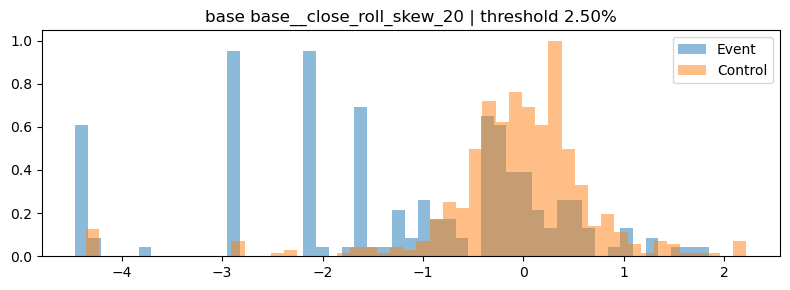

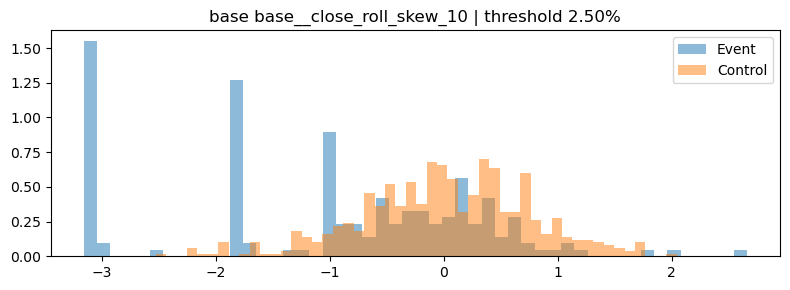

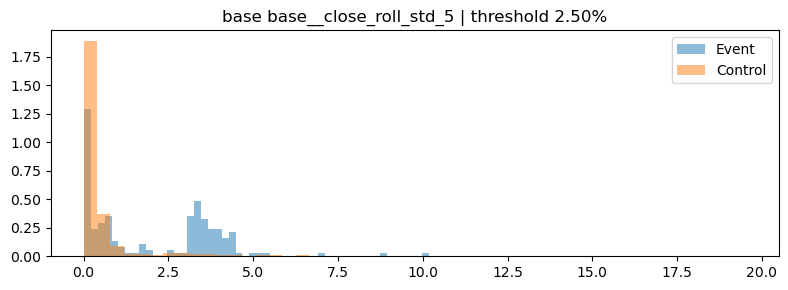

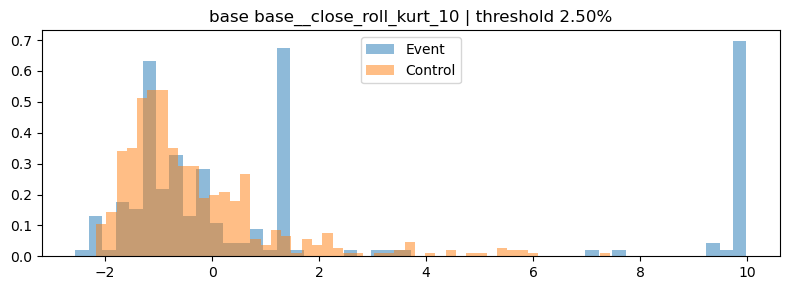

In [10]:
def plot_top(th, n=5):
    z=feature_stats[np.isclose(feature_stats.threshold,th)].sort_values("abs_smd",ascending=False)
    if z.empty: return
    er=rows_at(events[np.isclose(events.threshold,th)])
    cr=rows_at(controls[th])
    for f in z.feature.head(n):
        plt.figure(figsize=(8,3))
        plt.hist(vals(er[f]),bins=50,density=True,alpha=.5,label="Event")
        plt.hist(vals(cr[f]),bins=50,density=True,alpha=.5,label="Control")
        plt.title(f"{f} | threshold {th:.2%}")
        plt.legend(); plt.tight_layout(); plt.show()

for th in REVERSAL_THRESHOLDS: plot_top(th)


## 8. Сохранение результатов

In [11]:
events.to_csv(OUTPUT_DIR/"events_directional_change.csv",index=False)
pd.concat(controls.values(),ignore_index=True).to_csv(OUTPUT_DIR/"matched_random_controls.csv",index=False)
feature_stats.to_csv(OUTPUT_DIR/"event_vs_control_feature_stats.csv",index=False)
ticker_stats.to_csv(OUTPUT_DIR/"event_vs_control_ticker_stats.csv",index=False)
consistency_df.to_csv(OUTPUT_DIR/"event_vs_control_consistency.csv",index=False)
config=dict(tickers=TICKERS,start_date=START_DATE,end_date=END_DATE,
 thresholds=REVERSAL_THRESHOLDS,control_multiplier=CONTROL_MULTIPLIER,
 exclusion_radius_bars=EXCLUSION_RADIUS_BARS,tod_bucket_minutes=TOD_BUCKET_MINUTES,
 vol_lookback=VOL_LOOKBACK,vol_bins=VOL_BINS,feature_count=len(FEATURES),
 rows=len(data),events=len(events),seed=RANDOM_SEED,
 event_definition="Directional change; feature snapshot at pivot; confirmation by subsequent counter-move")
(OUTPUT_DIR/"run_config.json").write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding="utf-8")
print("Saved:",OUTPUT_DIR.resolve())


Saved: C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\research\event_vs_control_results


## 9. Интерпретация и ограничения

**Более убедительный результат:** `|SMD| >= 0.2` (лучше >= 0.5), низкий FDR q-value, одинаковый знак у большинства тикеров, эффект повторяется на нескольких порогах и периодах.

**Слабый результат:** статистическая значимость при почти нулевом SMD; эффект только у одного тикера; разнонаправленность между инструментами; исчезновение при небольшом изменении порога.

### Ограничения
1. Pivot размечается ретроспективно. Это допустимо для event study; нельзя использовать `confirmation_ts` или будущие данные как X.
2. События и бары зависимы во времени. Обычные p-values могут быть оптимистичны; следующий этап — block bootstrap по торговым дням.
3. Здесь close-only directional change. Для настоящего HFT понадобится аналогичный event detector на trade/quote stream, когда подтверждены корректные исторические данные.
4. Пороги в процентах намеренно не нормализованы на волатильность: это соответствует гипотезе, но позже полезно проверить volatility-scaled thresholds.
5. Отличие признаков в pivot-точках не доказывает, что экстремум можно предсказать заранее. Для этого нужен отдельный тест раннего обнаружения с измерением lead time.
6. Результат зависит от matching control; стоит проверить чувствительность к радиусу исключения и временным корзинам.

Notebook изолирован: не меняет production pipeline, live и risk-manager.
